In [28]:
!pip install faker

In [3]:
from faker import Faker
import pandas as pd
import numpy as np
import random
from datetime import timedelta

fake = Faker()
random.seed(42)
np.random.seed(42)

N_CUSTOMERS = 800
cities_clean = ["Cairo", "Alexandria", "Giza", "Tanta", "Mansoura", "Aswan", "Luxor", "Zagazig"]

customers = []
for i in range(1, N_CUSTOMERS + 1):
    customers.append({
        "customer_id": i,
        "name": fake.name(),
        "email": fake.unique.email(),
        "phone": fake.phone_number(),
        "city": random.choice(cities_clean),
        "gender": random.choice(["Male", "Female"]),
        "join_date": fake.date_between(start_date="-2y", end_date="-1M")
    })

df_customers = pd.DataFrame(customers)

categories = {
    "Electronics": ["Headphones", "Smartphone", "Laptop", "Smartwatch", "Tablet", "Speaker"],
    "Fashion": ["T-Shirt", "Jeans", "Jacket", "Sneakers", "Dress", "Cap"],
    "Home": ["Blender", "Lamp", "Cushion", "Curtains", "Mirror", "Rug"],
    "Beauty": ["Perfume", "Lotion", "Shampoo", "Lipstick", "Sunscreen"],
    "Books": ["Novel", "Notebook", "Comic", "Biography", "Cookbook"],
    "Sports": ["Yoga Mat", "Dumbbell", "Football", "Running Shoes", "Bicycle"],
}

products = []
product_id = 1
for category, items in categories.items():
    for item in items:
        for variant in range(1, random.randint(4, 7)):
            cost = round(random.uniform(50, 2000), 2)
            products.append({
                "product_id": product_id,
                "name": f"{item} {variant}",
                "category": category,
                "cost": cost,
                "price": round(cost * random.uniform(1.2, 1.8), 2),
                "stock_quantity": random.randint(0, 300),
                "supplier": fake.company()
            })
            product_id += 1

df_products = pd.DataFrame(products)

order_statuses = ["Delivered", "Shipped", "Processing", "Cancelled"]

orders = []
order_items = []
order_item_id = 1
order_id = 1

for cust in customers:
    n_orders = random.randint(1, 6)
    for _ in range(n_orders):
        order_date = fake.date_time_between(start_date=cust["join_date"], end_date="now")
        status = random.choice(order_statuses)

        n_items = random.randint(1, 5)
        chosen_products = random.sample(products, n_items)

        order_total = 0
        for p in chosen_products:
            qty = random.randint(1, 4)
            unit_price = p["price"]
            order_total += qty * unit_price
            order_items.append({
                "order_item_id": order_item_id,
                "order_id": order_id,
                "product_id": p["product_id"],
                "quantity": qty,
                "unit_price": unit_price
            })
            order_item_id += 1

        orders.append({
            "order_id": order_id,
            "customer_id": cust["customer_id"],
            "order_date": order_date,
            "status": status,
            "shipping_city": cust["city"],
            "total_amount": round(order_total, 2)
        })
        order_id += 1

df_orders = pd.DataFrame(orders)
df_order_items = pd.DataFrame(order_items)

payment_methods = ["Credit Card", "Cash on Delivery", "Mobile Wallet", "Bank Transfer"]

payments = []
payment_id = 1
for order in orders:
    if order["status"] != "Cancelled":
        pay_date = order["order_date"] + timedelta(days=random.randint(0, 2))
        payments.append({
            "payment_id": payment_id,
            "order_id": order["order_id"],
            "payment_method": random.choice(payment_methods),
            "amount": order["total_amount"],
            "payment_date": pay_date
        })
        payment_id += 1

df_payments = pd.DataFrame(payments)

reviews = []
review_id = 1
for _, row in df_order_items.sample(frac=0.35, random_state=42).iterrows():
    order = df_orders[df_orders["order_id"] == row["order_id"]].iloc[0]
    reviews.append({
        "review_id": review_id,
        "product_id": row["product_id"],
        "customer_id": order["customer_id"],
        "rating": random.randint(1, 5),
        "review_date": order["order_date"] + timedelta(days=random.randint(3, 20))
    })
    review_id += 1

df_reviews = pd.DataFrame(reviews)

def sprinkle_missing(df, cols, frac=0.05):
    for col in cols:
        idx = df.sample(frac=frac, random_state=random.randint(1, 9999)).index
        df.loc[idx, col] = np.nan
    return df

def dirty_city(city):
    choice = random.random()
    if choice < 0.25:
        return city.upper()
    elif choice < 0.5:
        return city.lower()
    elif choice < 0.7:
        return f"  {city}  "
    else:
        return city

df_customers = sprinkle_missing(df_customers, ["email", "phone"], frac=0.04)
df_customers["city"] = df_customers["city"].apply(dirty_city)
dup_customers = df_customers.sample(15, random_state=1)
df_customers = pd.concat([df_customers, dup_customers], ignore_index=True)

df_products["name"] = df_products["name"].apply(
    lambda x: f" {x} " if random.random() < 0.1 else x
)
neg_idx = df_products.sample(frac=0.03, random_state=2).index
df_products.loc[neg_idx, "stock_quantity"] = -1 * df_products.loc[neg_idx, "stock_quantity"]

outlier_idx = df_products.sample(frac=0.02, random_state=3).index
df_products.loc[outlier_idx, "price"] = df_products.loc[outlier_idx, "price"] * 50

df_orders = sprinkle_missing(df_orders, ["shipping_city"], frac=0.03)

dup_items = df_order_items.sample(20, random_state=4)
df_order_items = pd.concat([df_order_items, dup_items], ignore_index=True)

orphan_rows = pd.DataFrame([{
    "order_item_id": df_order_items["order_item_id"].max() + i + 1,
    "order_id": 999999 + i,
    "product_id": random.choice(df_products["product_id"].tolist()),
    "quantity": random.randint(1, 3),
    "unit_price": round(random.uniform(50, 500), 2)
} for i in range(5)])
df_order_items = pd.concat([df_order_items, orphan_rows], ignore_index=True)

df_payments = sprinkle_missing(df_payments, ["payment_method"], frac=0.04)

bad_rating_idx = df_reviews.sample(frac=0.03, random_state=5).index
df_reviews.loc[bad_rating_idx, "rating"] = df_reviews.loc[bad_rating_idx, "rating"].apply(
    lambda r: random.choice([0, 6])
)

df_customers.to_csv("customers_dirty.csv", index=False)
df_products.to_csv("products_dirty.csv", index=False)
df_orders.to_csv("orders_dirty.csv", index=False)
df_order_items.to_csv("order_items_dirty.csv", index=False)
df_payments.to_csv("payments_dirty.csv", index=False)
df_reviews.to_csv("reviews_dirty.csv", index=False)

print("Dirty dataset generated successfully")
print(f"Customers:   {len(df_customers)} rows  |  missing emails: {df_customers['email'].isna().sum()}")
print(f"Products:    {len(df_products)} rows  |  negative stock: {(df_products['stock_quantity'] < 0).sum()}")
print(f"Orders:      {len(df_orders)} rows  |  missing shipping_city: {df_orders['shipping_city'].isna().sum()}")
print(f"Order_Items: {len(df_order_items)} rows  |  orphan order_ids: 5 (manually injected)")
print(f"Payments:    {len(df_payments)} rows  |  missing payment_method: {df_payments['payment_method'].isna().sum()}")
print(f"Reviews:     {len(df_reviews)} rows  |  invalid ratings (0 or 6): {(~df_reviews['rating'].between(1,5)).sum()}")

Dirty dataset generated successfully
Customers:   815 rows  |  missing emails: 32
Products:    149 rows  |  negative stock: 4
Orders:      2757 rows  |  missing shipping_city: 83
Order_Items: 8206 rows  |  orphan order_ids: 5 (manually injected)
Payments:    2067 rows  |  missing payment_method: 83
Reviews:     2863 rows  |  invalid ratings (0 or 6): 86


In [4]:
df_customers = df_customers.drop_duplicates(subset="customer_id")
df_customers["city"] = df_customers["city"].str.strip().str.title()
df_customers["email"] = df_customers["email"].fillna("unknown@example.com")
df_customers["phone"] = df_customers["phone"].fillna("Unknown")

In [5]:
df_products["name"] = df_products["name"].str.strip()
df_products["stock_quantity"] = df_products["stock_quantity"].abs()
price_cap = df_products["price"].quantile(0.99)
df_products.loc[df_products["price"] > price_cap, "price"] = df_products["price"].median()

In [6]:
df_orders["shipping_city"] = df_orders["shipping_city"].fillna("Unknown")

In [7]:
df_order_items = df_order_items.drop_duplicates(subset="order_item_id")
valid_order_ids = df_orders["order_id"].unique()
df_order_items = df_order_items[df_order_items["order_id"].isin(valid_order_ids)]

In [8]:
df_payments["payment_method"] = df_payments["payment_method"].fillna("Unknown")

In [9]:
df_reviews = df_reviews[df_reviews["rating"].between(1, 5)]

In [10]:
df_customers.to_csv("customers_clean.csv", index=False)
df_products.to_csv("products_clean.csv", index=False)
df_orders.to_csv("orders_clean.csv", index=False)
df_order_items.to_csv("order_items_clean.csv", index=False)
df_payments.to_csv("payments_clean.csv", index=False)
df_reviews.to_csv("reviews_clean.csv", index=False)

In [11]:
print("Cleaning complete")
print(f"Customers:   {len(df_customers)} rows  |  missing emails: {df_customers['email'].isna().sum()}")
print(f"Products:    {len(df_products)} rows  |  negative stock: {(df_products['stock_quantity'] < 0).sum()}")
print(f"Orders:      {len(df_orders)} rows  |  missing shipping_city: {df_orders['shipping_city'].isna().sum()}")
print(f"Order_Items: {len(df_order_items)} rows")
print(f"Payments:    {len(df_payments)} rows  |  missing payment_method: {df_payments['payment_method'].isna().sum()}")
print(f"Reviews:     {len(df_reviews)} rows  |  invalid ratings: {(~df_reviews['rating'].between(1,5)).sum()}")

Cleaning complete
Customers:   800 rows  |  missing emails: 0
Products:    149 rows  |  negative stock: 0
Orders:      2757 rows  |  missing shipping_city: 0
Order_Items: 8181 rows
Payments:    2067 rows  |  missing payment_method: 0
Reviews:     2777 rows  |  invalid ratings: 0


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df_customers.head()

,customer_id,name,email,phone,city,gender,join_date
0,1,Amber Hunt,alopez@example.com,711.964.1474,Alexandria,Male,2024-11-14
1,2,Samuel Church,lori97@example.com,+1-730-397-9071x82595,Mansoura,Male,2025-07-11
2,3,Lawrence Anderson,jimenezgary@example.com,+1-819-548-6664x041,Tanta,Male,2024-11-18
3,4,Patrick Ruiz,unknown@example.com,(761)613-0621x749,Alexandria,Male,2024-09-25
4,5,Robert Frederick,krista38@example.com,001-227-373-5145,Luxor,Male,2025-07-02


In [26]:
df_customers.tail()

,customer_id,name,email,phone,city,gender,join_date
795,796,Donna Davis,sarahparker@example.net,001-539-443-3382x51388,Mansoura,Male,2025-07-17
796,797,Shelly Thompson,joseph58@example.net,001-927-402-4095,Mansoura,Male,2025-10-09
797,798,Kevin Barnes,djacobs@example.com,303.464.2268x88502,Giza,Male,2025-09-18
798,799,Sarah Williams,mario96@example.org,001-289-624-2390x38135,Giza,Female,2024-12-26
799,800,Scott Walker,jenniferstevens@example.org,4943139288,Cairo,Male,2026-03-23


In [27]:
df_reviews.shape

(2777, 5)

In [14]:
df_customers = pd.read_csv("customers_clean.csv")
df_products = pd.read_csv("products_clean.csv")
df_orders = pd.read_csv("orders_clean.csv", parse_dates=["order_date"])
df_order_items = pd.read_csv("order_items_clean.csv")
df_payments = pd.read_csv("payments_clean.csv")
df_reviews = pd.read_csv("reviews_clean.csv")

sns.set_theme(style="whitegrid")

In [15]:
delivered_orders = df_orders[df_orders["status"] != "Cancelled"].copy()
delivered_orders["month"] = delivered_orders["order_date"].dt.to_period("M").astype(str)

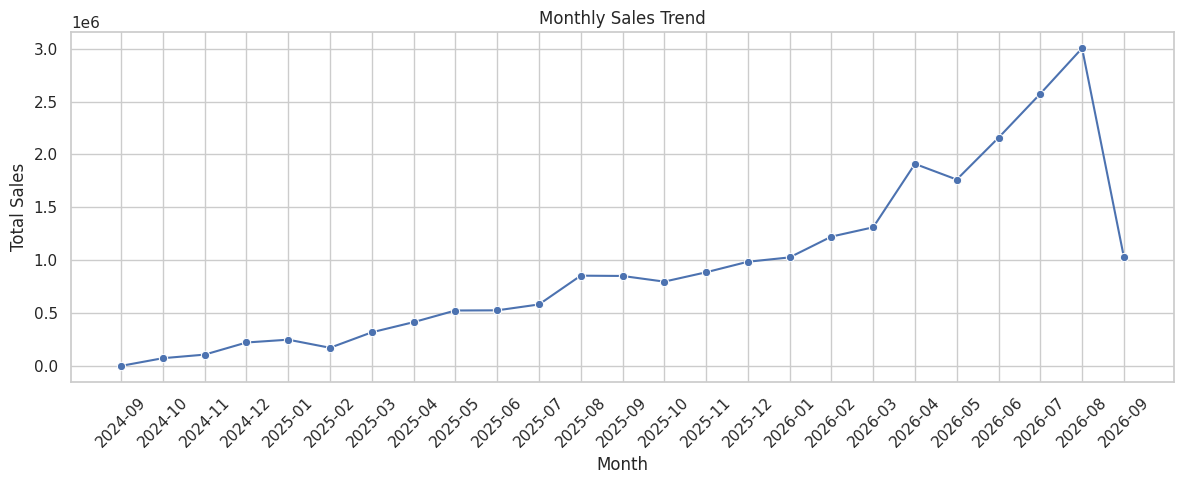

In [16]:
monthly_sales = delivered_orders.groupby("month")["total_amount"].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x="month", y="total_amount", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("monthly_sales_trend.png")
plt.show()

In [17]:
items_with_products = df_order_items.merge(df_products, on="product_id")
items_with_products["line_total"] = items_with_products["quantity"] * items_with_products["unit_price"]

/tmp/ipykernel_955/1525833164.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products, y="name", x="line_total", palette="viridis")


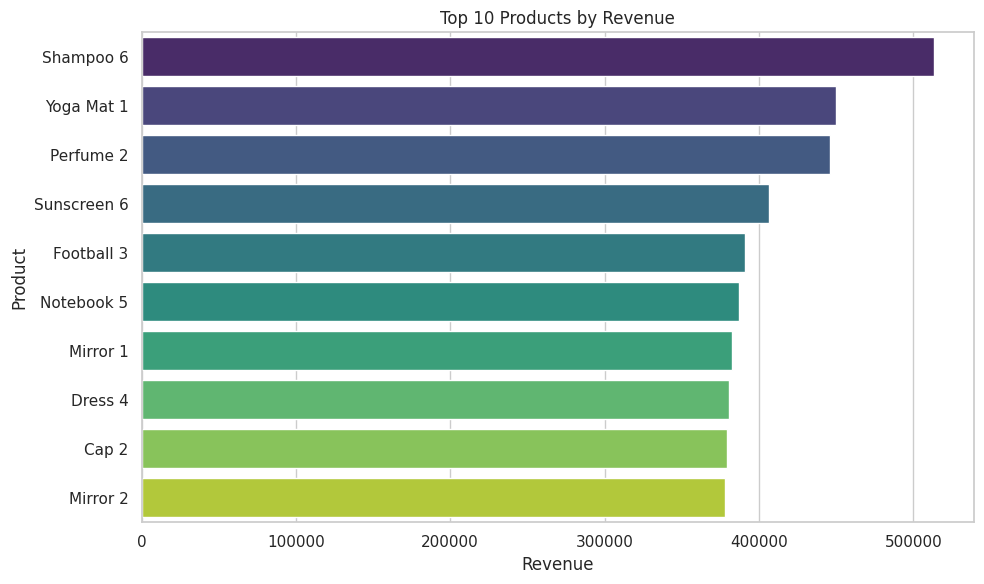

In [18]:
top_products = (
    items_with_products.groupby("name")["line_total"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_products, y="name", x="line_total", palette="viridis")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("top_products.png")
plt.show()

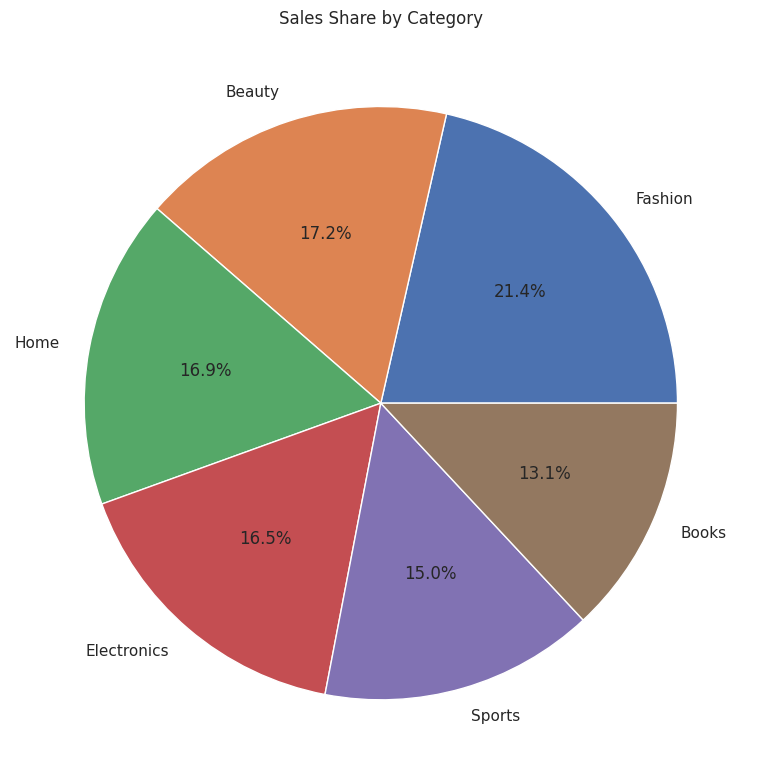

In [19]:
category_sales = (
    items_with_products.groupby("category")["line_total"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 8))
plt.pie(category_sales["line_total"], labels=category_sales["category"], autopct="%1.1f%%")
plt.title("Sales Share by Category")
plt.tight_layout()
plt.savefig("category_sales_share.png")
plt.show()

In [20]:
customer_spend = (
    delivered_orders.groupby("customer_id")["total_amount"]
    .sum()
    .reset_index()
    .rename(columns={"total_amount": "total_spend"})
)

customer_orders_count = (
    delivered_orders.groupby("customer_id")["order_id"]
    .count()
    .reset_index()
    .rename(columns={"order_id": "order_count"})
)

customer_summary = customer_spend.merge(customer_orders_count, on="customer_id")
customer_summary = customer_summary.merge(df_customers, on="customer_id")


In [21]:
spend_high = customer_summary["total_spend"].quantile(0.75)
spend_low = customer_summary["total_spend"].quantile(0.25)

def segment(spend):
    if spend >= spend_high:
        return "High Value"
    elif spend <= spend_low:
        return "Low Value"
    else:
        return "Medium Value"

customer_summary["segment"] = customer_summary["total_spend"].apply(segment)

/tmp/ipykernel_955/1209815110.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_counts, x="segment", y="count", palette="magma")


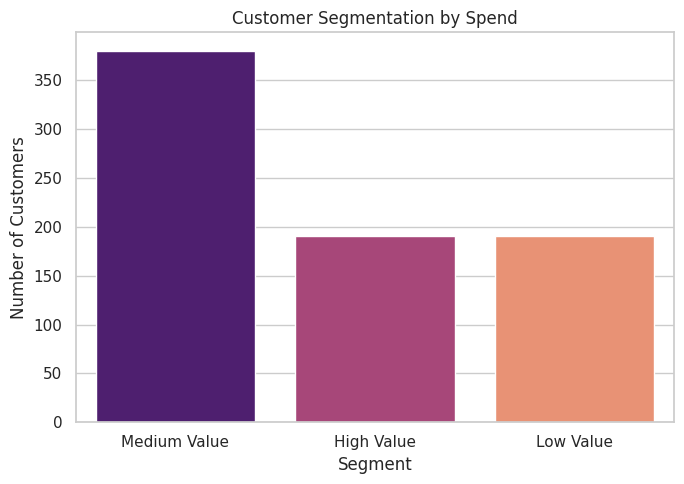

In [22]:
segment_counts = customer_summary["segment"].value_counts().reset_index()
segment_counts.columns = ["segment", "count"]

plt.figure(figsize=(7, 5))
sns.barplot(data=segment_counts, x="segment", y="count", palette="magma")
plt.title("Customer Segmentation by Spend")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("customer_segments.png")
plt.show()

In [23]:
avg_order_value = delivered_orders["total_amount"].mean()
avg_rating = df_reviews["rating"].mean()

print(f"Average Order Value: {avg_order_value:.2f}")
print(f"Average Product Rating: {avg_rating:.2f}")
print(f"Top spending customer: {customer_summary.sort_values('total_spend', ascending=False).iloc[0]['name']}")
print("\nSegment breakdown:")
print(segment_counts.to_string(index=False))

Average Order Value: 11399.56
Average Product Rating: 3.00
Top spending customer: Christine Lewis

Segment breakdown:
     segment  count
Medium Value    380
  High Value    191
   Low Value    191


In [24]:
customer_summary.to_csv("customer_segmentation.csv", index=False)
top_products.to_csv("top_products_analysis.csv", index=False)
category_sales.to_csv("category_sales_analysis.csv", index=False)